# Tema 2 Machine Learning - Images Classificator
## Mandescu Victor-Ioan 342C4

In [51]:
%pip install matplotlib
%pip install Pillow
%pip install torchvision
%pip install torch

from PIL import Image
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import numpy as np
import os
import matplotlib.pyplot as plt
import random
import torch
import torchvision

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [52]:
# img_path = 'images/imagebits/imagebits/train/1/3.png'
# image = Image.open(img_path)
# img_array = np.array(image)
# print(f"Shape-ul matricei: {img_array.shape}")
# image.show()

## Exploratory data analysis for image classification - imagebits

Class 1:
  Number of images in the training set: 800
  Number of images in the test set: 500
Class 2:
  Number of images in the training set: 800
  Number of images in the test set: 500
Class 3:
  Number of images in the training set: 800
  Number of images in the test set: 500
Class 4:
  Number of images in the training set: 800
  Number of images in the test set: 500
Class 5:
  Number of images in the training set: 800
  Number of images in the test set: 500
Class 6:
  Number of images in the training set: 800
  Number of images in the test set: 500
Class 7:
  Number of images in the training set: 800
  Number of images in the test set: 500
Class 8:
  Number of images in the training set: 800
  Number of images in the test set: 500
Class 9:
  Number of images in the training set: 800
  Number of images in the test set: 500
Class 10:
  Number of images in the training set: 800
  Number of images in the test set: 500


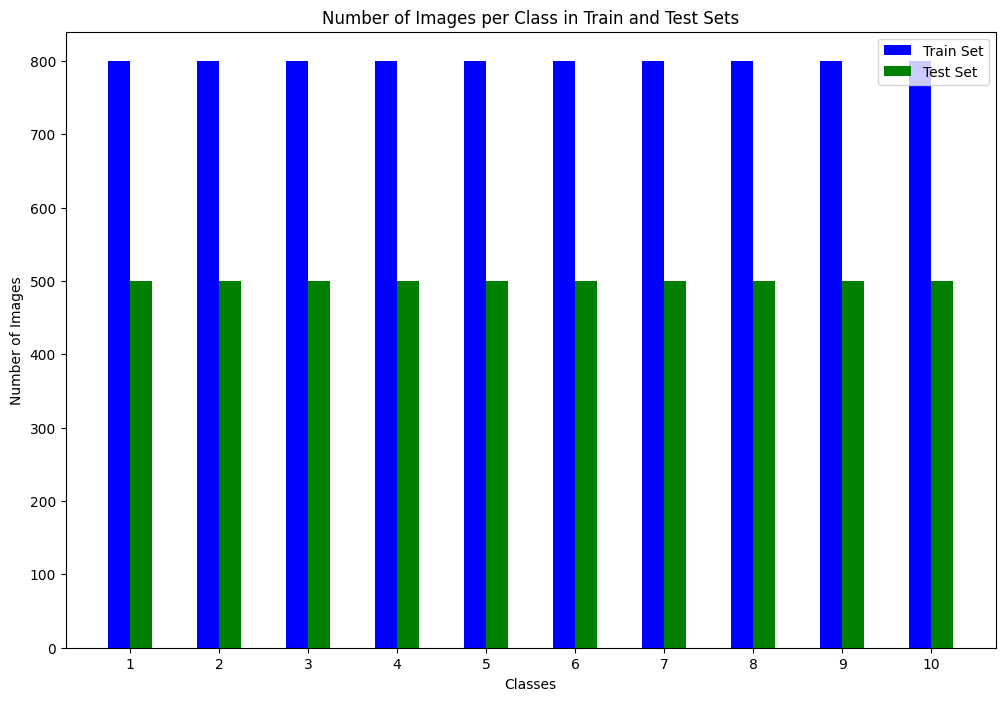

In [53]:
img_train_dir_path = 'images/imagebits/imagebits/train/'
img_test_dir_path = 'images/imagebits/imagebits/test/'
number_classes = {}

for i in range(1, 11):
    train_class_dir = os.path.join(img_train_dir_path, str(i))
    test_class_dir = os.path.join(img_test_dir_path, str(i))
    
    train_images = os.listdir(train_class_dir)
    test_images = os.listdir(test_class_dir)

    number_classes[i] = {
        'train_count': len(train_images),
        'test_count': len(test_images)
    }
    
    print(f"Class {i}:")
    print(f"  Number of images in the training set: {len(train_images)}")
    print(f"  Number of images in the test set: {len(test_images)}")

labels = list(number_classes.keys())
train_vals = [v['train_count'] for v in number_classes.values()]
test_vals = [v['test_count'] for v in number_classes.values()]

x = np.arange(len(labels))
width = 0.25

fig = plt.subplots(figsize=(12, 8))
plt.bar(x - width/2, train_vals, width, label='Train Set', color='blue')
plt.bar(x + width/2, test_vals, width, label='Test Set', color='green')

plt.xlabel('Classes')
plt.ylabel('Number of Images')
plt.title('Number of Images per Class in Train and Test Sets')
plt.xticks(x, labels)
plt.legend()
plt.show()

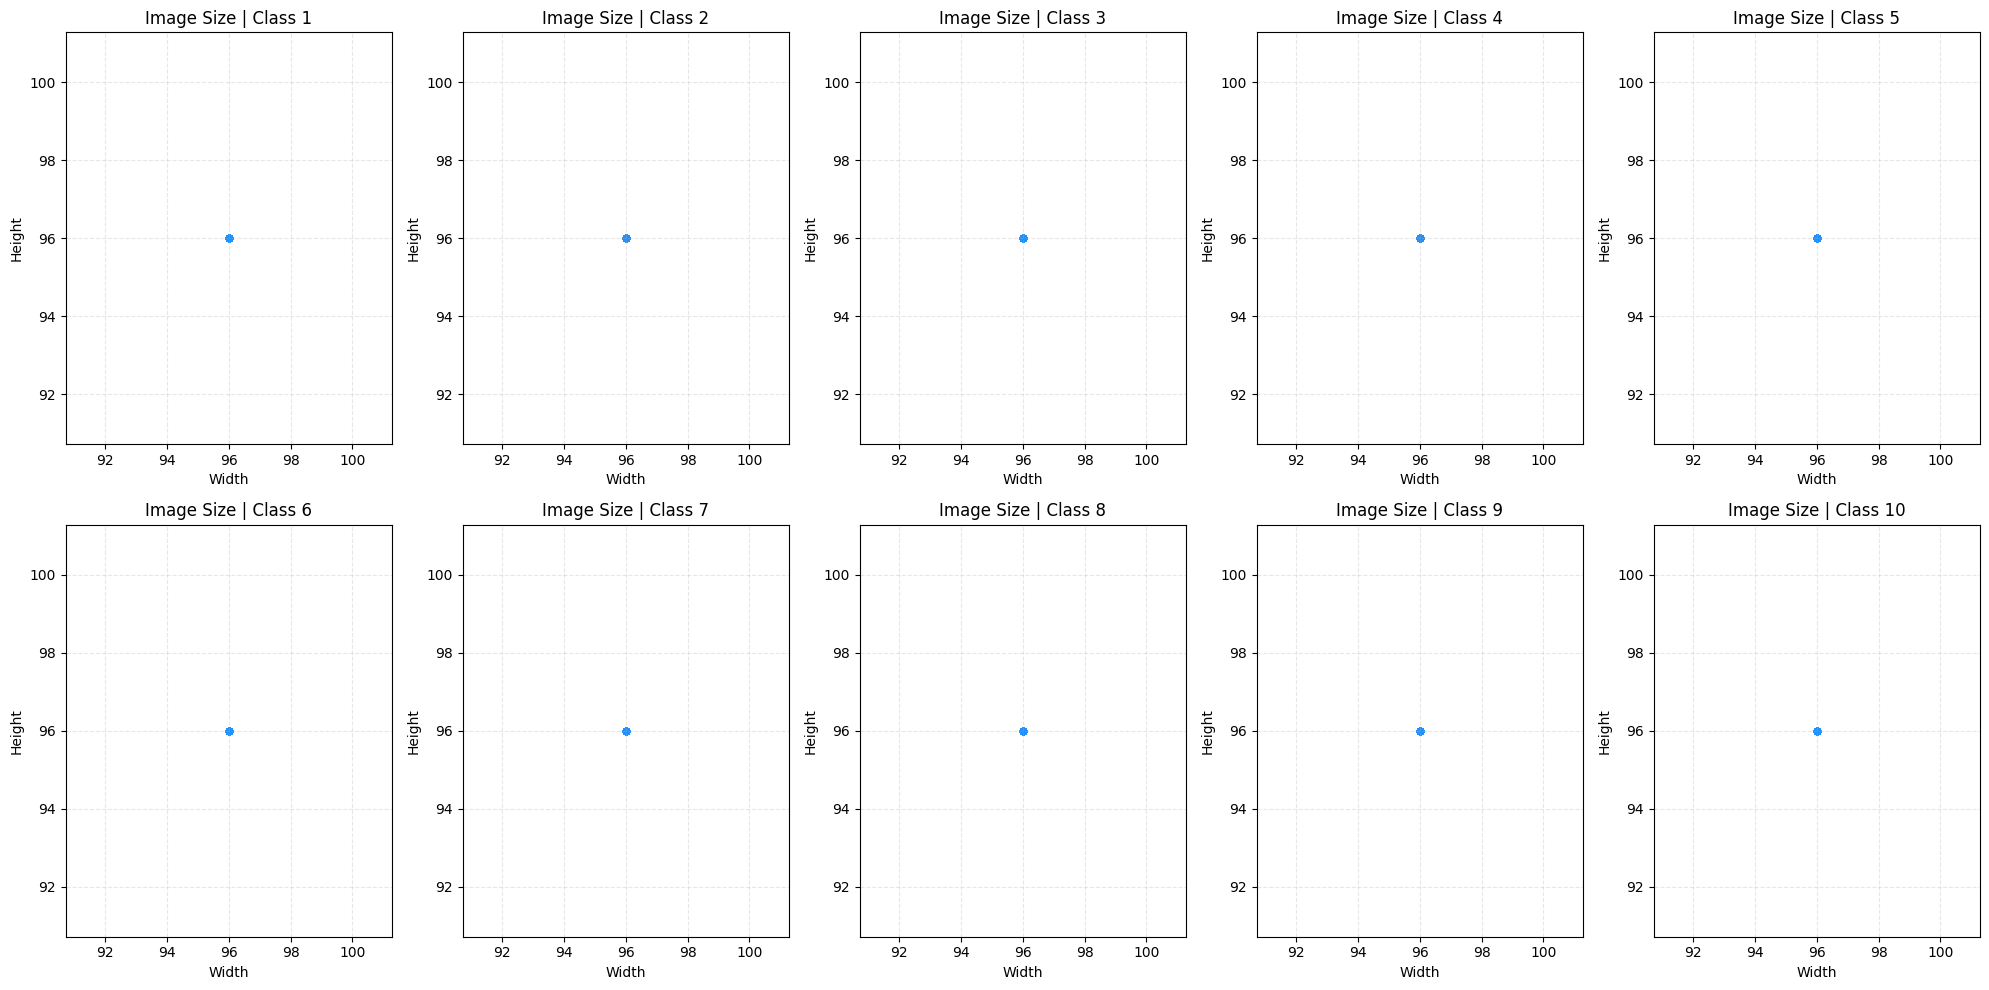

In [54]:
class_data = {}

for i in range(1, 11):
    class_dir = os.path.join(img_train_dir_path, str(i))
    images = os.listdir(class_dir)
    
    widths = []
    heights = []
    
    for img_name in images:
        if img_name.lower().endswith(('.png', '.jpg')):
            img_path = os.path.join(class_dir, img_name)
            with Image.open(img_path) as img:
                w, h = img.size
                widths.append(w)
                heights.append(h)

    class_data[i] = {'w': widths, 'h': heights}

fig = plt.subplots(nrows=2, ncols=5, figsize=(20, 10))

for idx, class_id in enumerate(range(1, 11)):
    ax = plt.subplot(2, 5, idx + 1)

    w = class_data[class_id]['w']
    h = class_data[class_id]['h']

    ax.scatter(w, h, alpha=0.5, s=20, color='dodgerblue')
    ax.set_title(f'Image Size | Class {class_id}')
    ax.set_xlabel('Width')
    ax.set_ylabel('Height')
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

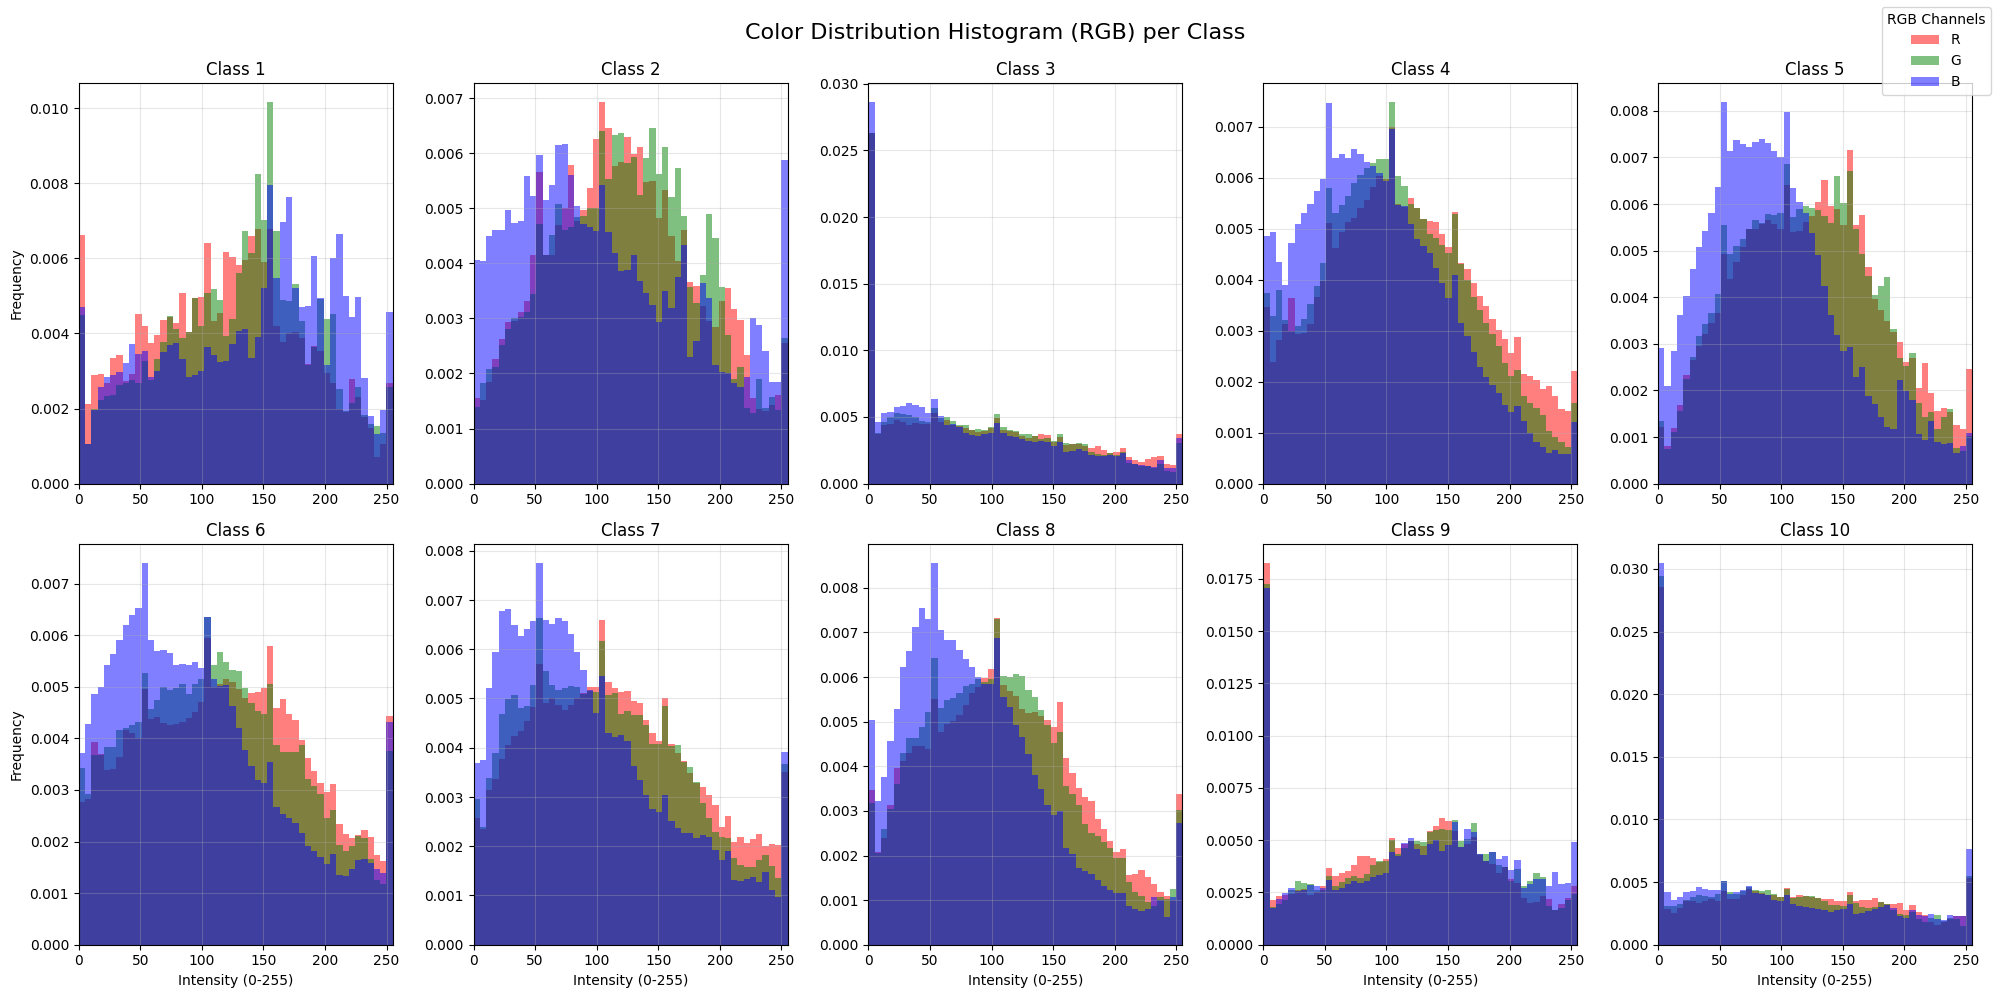

In [55]:
import matplotlib.pyplot as plt
import os
import numpy as np
from PIL import Image

fig, _ = plt.subplots(nrows=2, ncols=5, figsize=(20, 10))

for idx, class_id in enumerate(range(1, 11)):
    class_dir = os.path.join(img_train_dir_path, str(class_id))
 
    images = os.listdir(class_dir)
    if len(images) > 100:
        images = images[:100]

    all_reds = []
    all_greens = []
    all_blues = []
    
    for img_name in images:
        if img_name.lower().endswith(('.png', '.jpg')):
            img_path = os.path.join(class_dir, img_name)
            try:
                with Image.open(img_path).convert('RGB') as img:
                    img_array = np.array(img)
                    all_reds.extend(img_array[:, :, 0].flatten())
                    all_greens.extend(img_array[:, :, 1].flatten())
                    all_blues.extend(img_array[:, :, 2].flatten())
            except:
                pass

    ax = plt.subplot(2, 5, idx + 1)
    ax.hist(all_reds, bins=50, color='red', alpha=0.5, label='R', density=True)
    ax.hist(all_greens, bins=50, color='green', alpha=0.5, label='G', density=True)
    ax.hist(all_blues, bins=50, color='blue', alpha=0.5, label='B', density=True)
    ax.set_title(f'Class {class_id}')
    ax.set_xlim(0, 255)
    
    if idx % 5 == 0:
        ax.set_ylabel('Frequency')
    if idx >= 5:
        ax.set_xlabel('Intensity (0-255)')
        
    ax.grid(True, alpha=0.3)

handles, labels = plt.gca().get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', title="RGB Channels")

plt.suptitle("Color Distribution Histogram (RGB) per Class", fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

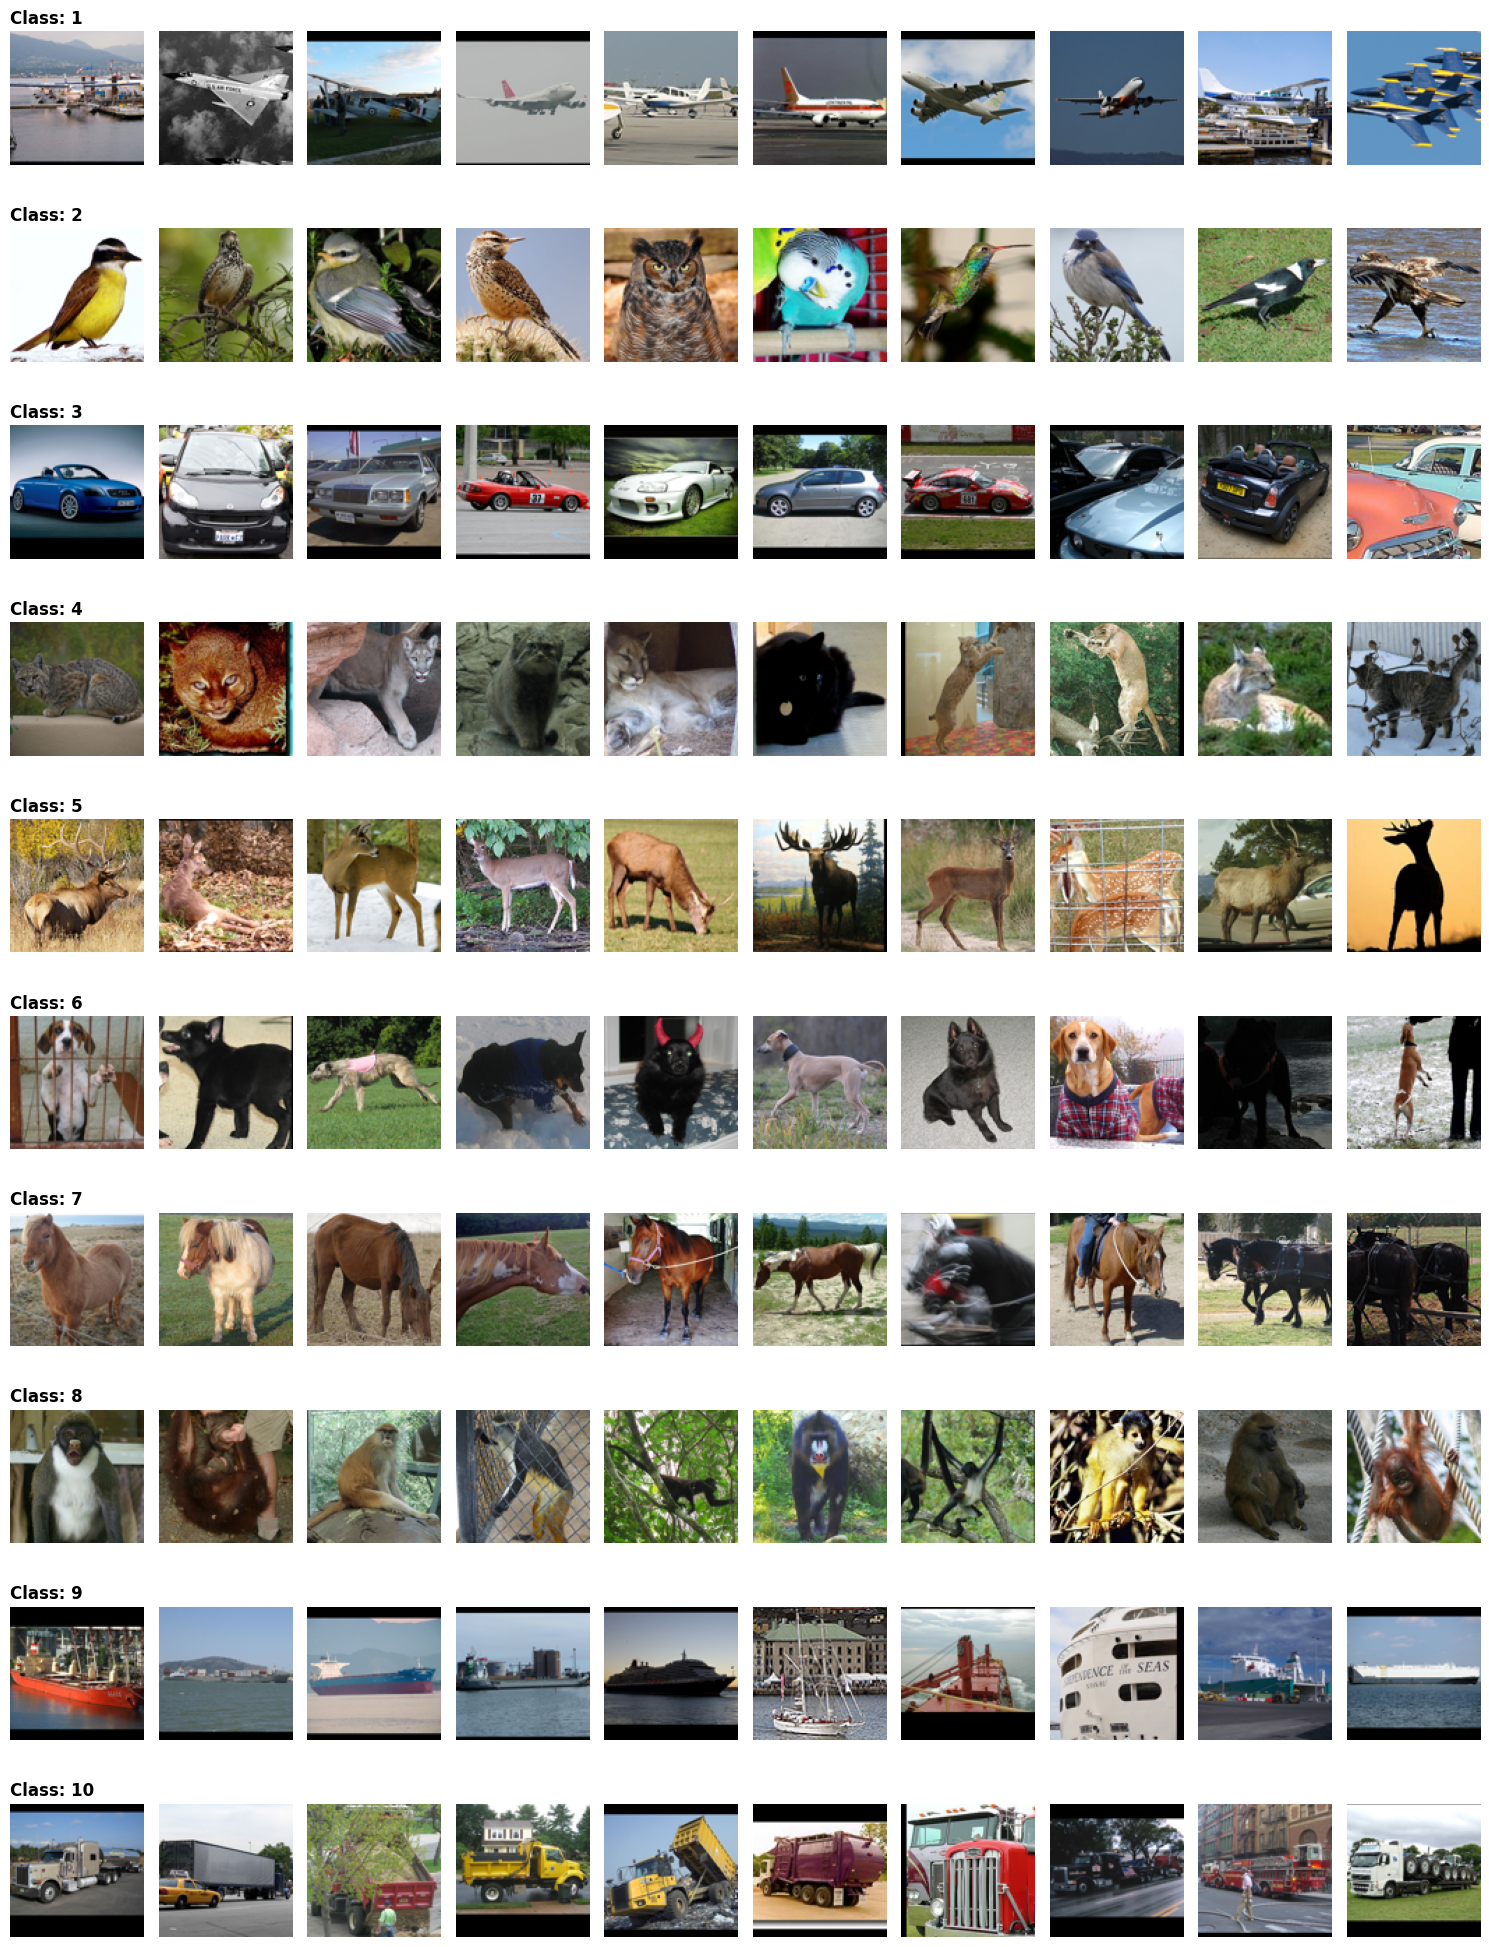

In [56]:
fig, axes = plt.subplots(nrows=len(range(1, 11)), ncols=10, figsize=(15, 20))

for row_idx, class_id in enumerate(range(1, 11)):
    class_dir = os.path.join(img_train_dir_path, str(class_id))   
    all_imgs = [f for f in os.listdir(class_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    
    current_samples = random.sample(all_imgs, min(len(all_imgs), 10))
    for col_idx, img_name in enumerate(current_samples):
        img_path = os.path.join(class_dir, img_name)
        with Image.open(img_path) as img:
            ax = axes[row_idx, col_idx]
            ax.imshow(img)
            ax.axis('off')
            
            if col_idx == 0:
                ax.set_title(f'Class: {class_id}', fontsize=12, fontweight='bold', loc='left')

plt.tight_layout()
plt.show()

In [57]:
import torchvision

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Running on device: {device}")

train_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

test_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

train_images = torchvision.datasets.ImageFolder(root=img_train_dir_path, transform=train_transform)
test_images = torchvision.datasets.ImageFolder(root=img_test_dir_path, transform=test_transform)

print(f'Size of training labels {len(train_images.targets)}')
print(f'Size of test labels {len(test_images.targets)}')

Running on device: cpu
Size of training labels 8000
Size of test labels 5000


In [58]:
BATCH_SIZE_TRAIN = 100
BATCH_SIZE_TEST = 100
NO_WORKERS = 8
SHUFFLE_DATA = True

train_loader = torch.utils.data.DataLoader(train_images, batch_size=BATCH_SIZE_TRAIN, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)
(batch_train_images, batch_train_labels) = next(iter(train_loader))

print(f'Shape of training images: {batch_train_images.size()}')
print(f'Shape of training labels: {batch_train_labels.size()}')

Shape of training images: torch.Size([100, 3, 96, 96])
Shape of training labels: torch.Size([100])


In [59]:
test_loader = torch.utils.data.DataLoader(test_images, batch_size=BATCH_SIZE_TRAIN, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)

def loopy_test_loader(dl):
    data_iter = iter(dl)

    while True:
        try:
            yield next(data_iter)
        except StopIteration:
            data_iter = iter(dl)
            yield next(data_iter)

(batch_test_images, batch_test_labels) = next(iter(test_loader))
print(f'Shape of test images: {batch_test_images.size()}')
print(f'Shape of test labels: {batch_test_labels.size()}')

Shape of test images: torch.Size([100, 3, 96, 96])
Shape of test labels: torch.Size([100])


In [60]:
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, img_size = 96, num_classes=10):
        super(MLP, self).__init__()
       
        self.in_size = 3 * img_size * img_size

        self.fc1 = nn.Linear(self.in_size, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, num_classes)

        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(p=0.5)

    def forward(self, x):
        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))
        x = self.dropout(x)

        x = self.relu(self.fc2(x))
        x = self.dropout(x)
        
        x = self.fc3(x)

        return x

In [61]:
from torch import device

def get_num_params(model):
    num_params = 0
    for params in model.parameters():
        num_params += params.shape.numel()

    return num_params

def top_k_accuracy(k, target, output):
    batch_size = target.size(0)

    _, pred = output.topk(k, 1, True, True)

    pred = pred.t()
    correct = pred.eq(target.to(device).view(1, -1).expand_as(pred))

    correct_k = correct[:k].view(-1).float().sum(0, keepdim=True)
    correct_k.mul_(100.0 / batch_size)

    return correct_k


In [63]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

net = MLP(img_size=96, num_classes=10).to(device)
print(f"Model Parameters: {get_num_params(net)}")

lr_init = 0.001
lr_factor = 0.1
weight_decay_factor = 1e-4
lr_schedule_milestones = [50e3, 75e3, 100e3] 
flag_regularize = True 

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(net.parameters(), lr=lr_init)

if flag_regularize:
    optimizer = torch.optim.Adam(net.parameters(), lr=lr_init, weight_decay=weight_decay_factor)

lr_scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=lr_schedule_milestones, gamma=lr_factor)

Model Parameters: 14290186


In [64]:
import matplotlib.pyplot as pl
from IPython import display
import time

REFRESH_EVERY = 1000

def plot_losses(loss_list, steps, ct):
    if ct % REFRESH_EVERY == 0:
        display.clear_output(wait=True)

    display.display(pl.gcf())
    pl.plot(steps, loss_list, c='b')
    time.sleep(1.0)

In [65]:
TRAIN_ITERS = 100e3
REPORT_TRAIN_EVERY = 100
PLOT_EVERY = 100
REPORT_TEST_EVERY = 200
TEST_ITERS = 100

<Figure size 640x480 with 0 Axes>

[2,    20,     99] LR: 0.00100
[2,    20] loss: 2.26671, acc: 23.78000


c:\Users\victo\Desktop\Laboratoare ML\Tema2\.venv\Lib\site-packages\torch\optim\lr_scheduler.py:578: UserWarning: To get the last learning rate computed by the scheduler, please use `get_last_lr()`.
  _warn_get_lr_called_within_step(self)


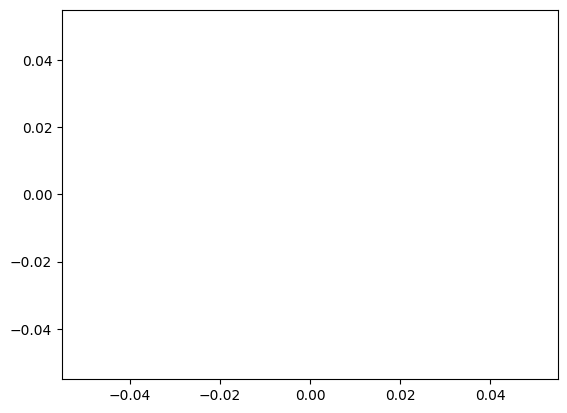

[3,    40,    199] LR: 0.00100
[3,    40] loss: 1.89337, acc: 29.68000
[3,    40] avg_test_loss: 1.77653, avg_test_acc: 35.24


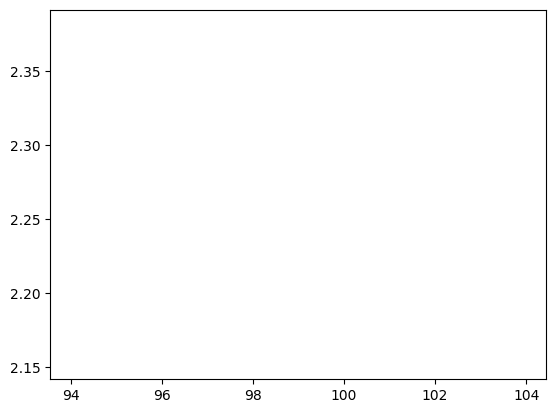

[4,    60,    299] LR: 0.00100
[4,    60] loss: 1.83757, acc: 31.54000


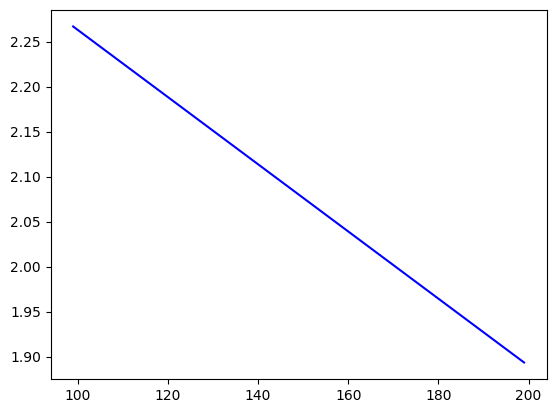

[5,    80,    399] LR: 0.00100
[5,    80] loss: 1.82068, acc: 31.95000
[5,    80] avg_test_loss: 1.73003, avg_test_acc: 36.52


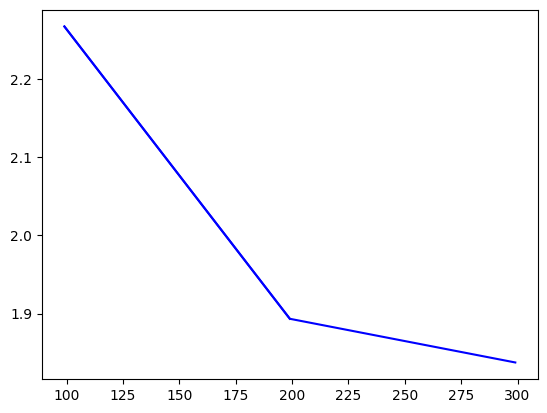

[7,    20,    499] LR: 0.00100
[7,    20] loss: 1.78247, acc: 33.18000


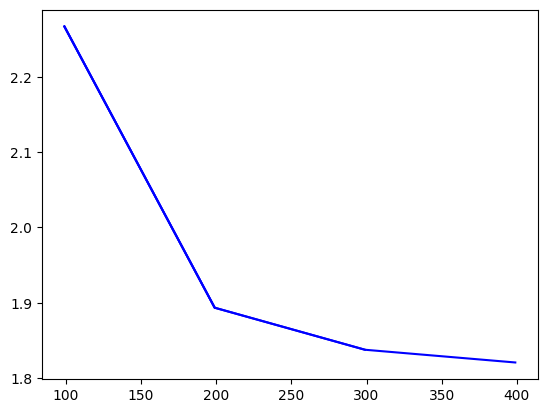

[8,    40,    599] LR: 0.00100
[8,    40] loss: 1.77157, acc: 33.78000
[8,    40] avg_test_loss: 1.72357, avg_test_acc: 37.00


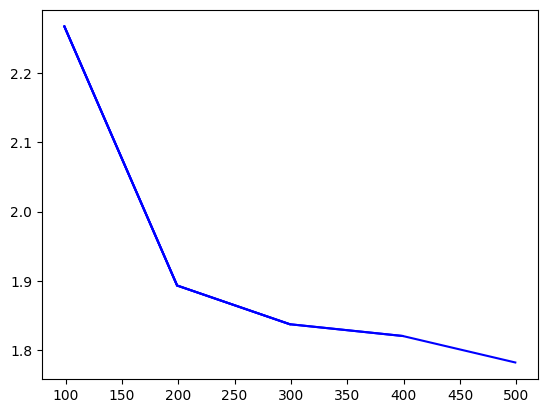

Finished Training


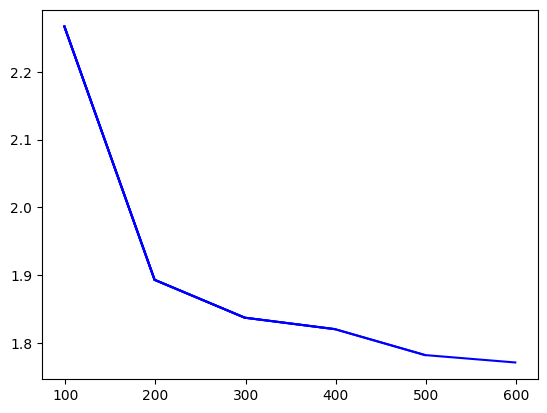

In [66]:
EPOCHS = 8

train_iter = 0
losses = []
steps = []

test_data_provider = loopy_test_loader(test_loader)

net.train()

running_loss = 0.0
running_acc = 0.0
ct = 0

for epoch in range(int(EPOCHS)):

    for i, data in enumerate(train_loader, 0):
        lr_scheduler.step()

        inputs, labels = data[0].to(device), data[1].to(device)

        optimizer.zero_grad()

        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        running_acc += top_k_accuracy(1, labels, outputs)

        if train_iter % REPORT_TRAIN_EVERY == REPORT_TRAIN_EVERY - 1:
            train_loss = running_loss / REPORT_TRAIN_EVERY
            train_acc = running_acc / REPORT_TRAIN_EVERY

            print('[%d, %5d, %6d] LR: %.5f' % (epoch + 1, i + 1, train_iter, lr_scheduler.get_lr()[-1]))
            print('[%d, %5d] loss: %.5f, acc: %.5f' %
                  (epoch + 1, i + 1, train_loss, train_acc))

            losses.append(train_loss)
            steps.append(train_iter)

            running_loss = 0
            train_loss = 0
            running_acc = 0

        if train_iter % PLOT_EVERY == 0:
            plot_losses(losses, steps, train_iter)

        train_iter += 1

        if train_iter % REPORT_TEST_EVERY == 0:
            net.eval()

            with torch.no_grad():
                test_iter = 0
                test_loss = 0
                correct = 0

                while test_iter < TEST_ITERS:
                    test_data = next(test_data_provider)
                    test_inputs, test_labels = test_data[0].to(device), test_data[1].to(device)

                    out = net(test_inputs)
                    test_loss += criterion(out, test_labels)

                    correct += top_k_accuracy(1, test_labels, out)

                    test_iter += 1

                avg_test_loss = test_loss / TEST_ITERS
                avg_acc = correct / TEST_ITERS

                print('[%d, %5d] avg_test_loss: %.5f, avg_test_acc: %.2f'
                    % (epoch + 1, i + 1, avg_test_loss, avg_acc))

            net.train()

print('Finished Training')

## Exploratory data analysis for image classification - land_patches

Class 'AnnualCrop': Train=200, Test=700, Val=100
Class 'Forest': Train=200, Test=700, Val=100
Class 'HerbaceousVegetation': Train=200, Test=700, Val=100
Class 'Highway': Train=200, Test=700, Val=100
Class 'Industrial': Train=200, Test=700, Val=100
Class 'Pasture': Train=200, Test=700, Val=100
Class 'PermanentCrop': Train=200, Test=700, Val=100
Class 'Residential': Train=200, Test=700, Val=100
Class 'River': Train=200, Test=700, Val=100
Class 'SeaLake': Train=200, Test=700, Val=100


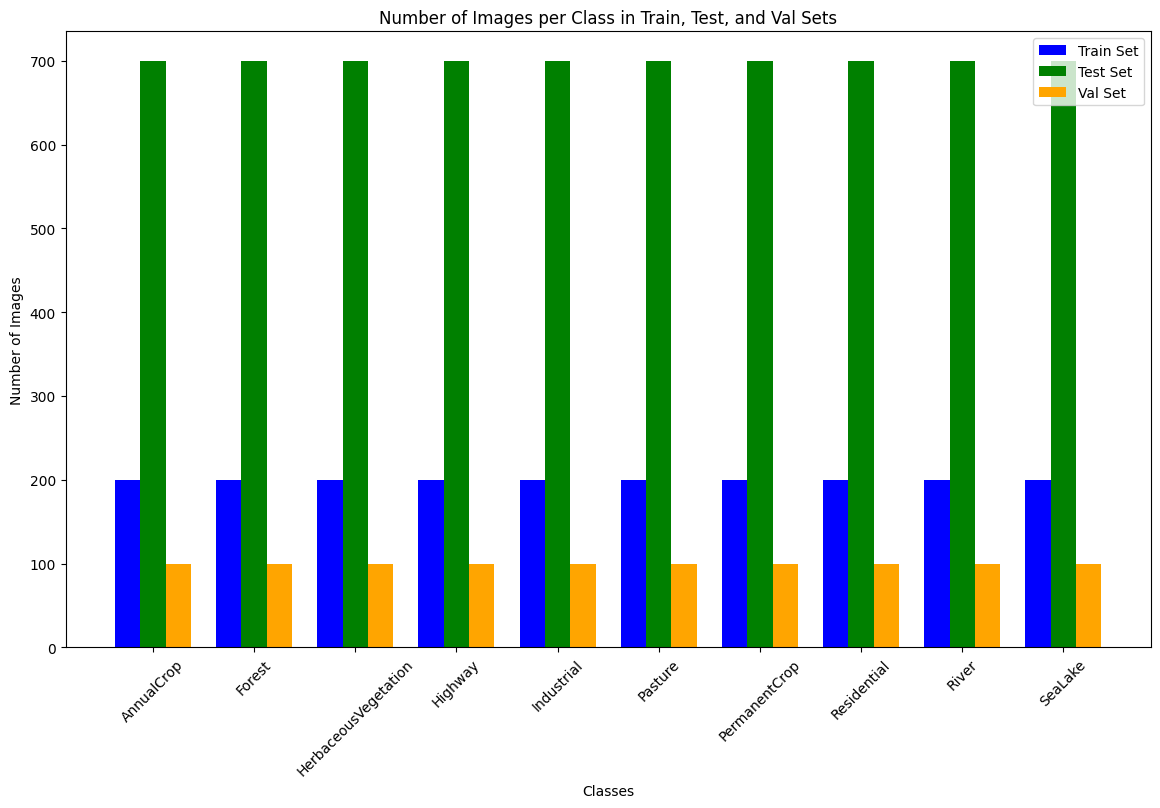

In [7]:
land_patches_train_dir_path = 'images/land_patches/land_patches/train/'
land_patches_test_dir_path = 'images/land_patches/land_patches/test/'
land_patches_val_dir_path = 'images/land_patches/land_patches/val/'

class_names = [d for d in os.listdir(land_patches_train_dir_path) 
               if os.path.isdir(os.path.join(land_patches_train_dir_path, d))]
class_names.sort()

number_classes = {}
for class_name in class_names:
    train_class_dir = os.path.join(land_patches_train_dir_path, class_name)
    test_class_dir = os.path.join(land_patches_test_dir_path, class_name)
    val_class_dir = os.path.join(land_patches_val_dir_path, class_name)
    
    train_count = len(os.listdir(train_class_dir))
    test_count = len(os.listdir(test_class_dir))
    val_count = len(os.listdir(val_class_dir))

    number_classes[class_name] = {
        'train_count': train_count,
        'test_count': test_count,
        'val_count': val_count
    }
    
    print(f"Class '{class_name}': Train={train_count}, Test={test_count}, Val={val_count}")

labels = list(number_classes.keys())
train_vals = [v['train_count'] for v in number_classes.values()]
test_vals = [v['test_count'] for v in number_classes.values()]
val_vals = [v['val_count'] for v in number_classes.values()]

x = np.arange(len(labels))
width = 0.25 

fig = plt.subplots(figsize=(14, 8))
plt.bar(x - width, train_vals, width, label='Train Set', color='blue')
plt.bar(x, test_vals, width, label='Test Set', color='green')
plt.bar(x + width, val_vals, width, label='Val Set', color='orange')
plt.xlabel('Classes')
plt.ylabel('Number of Images')
plt.title('Number of Images per Class in Train, Test, and Val Sets')
plt.xticks(x, labels, rotation=45)
plt.legend()
plt.show()

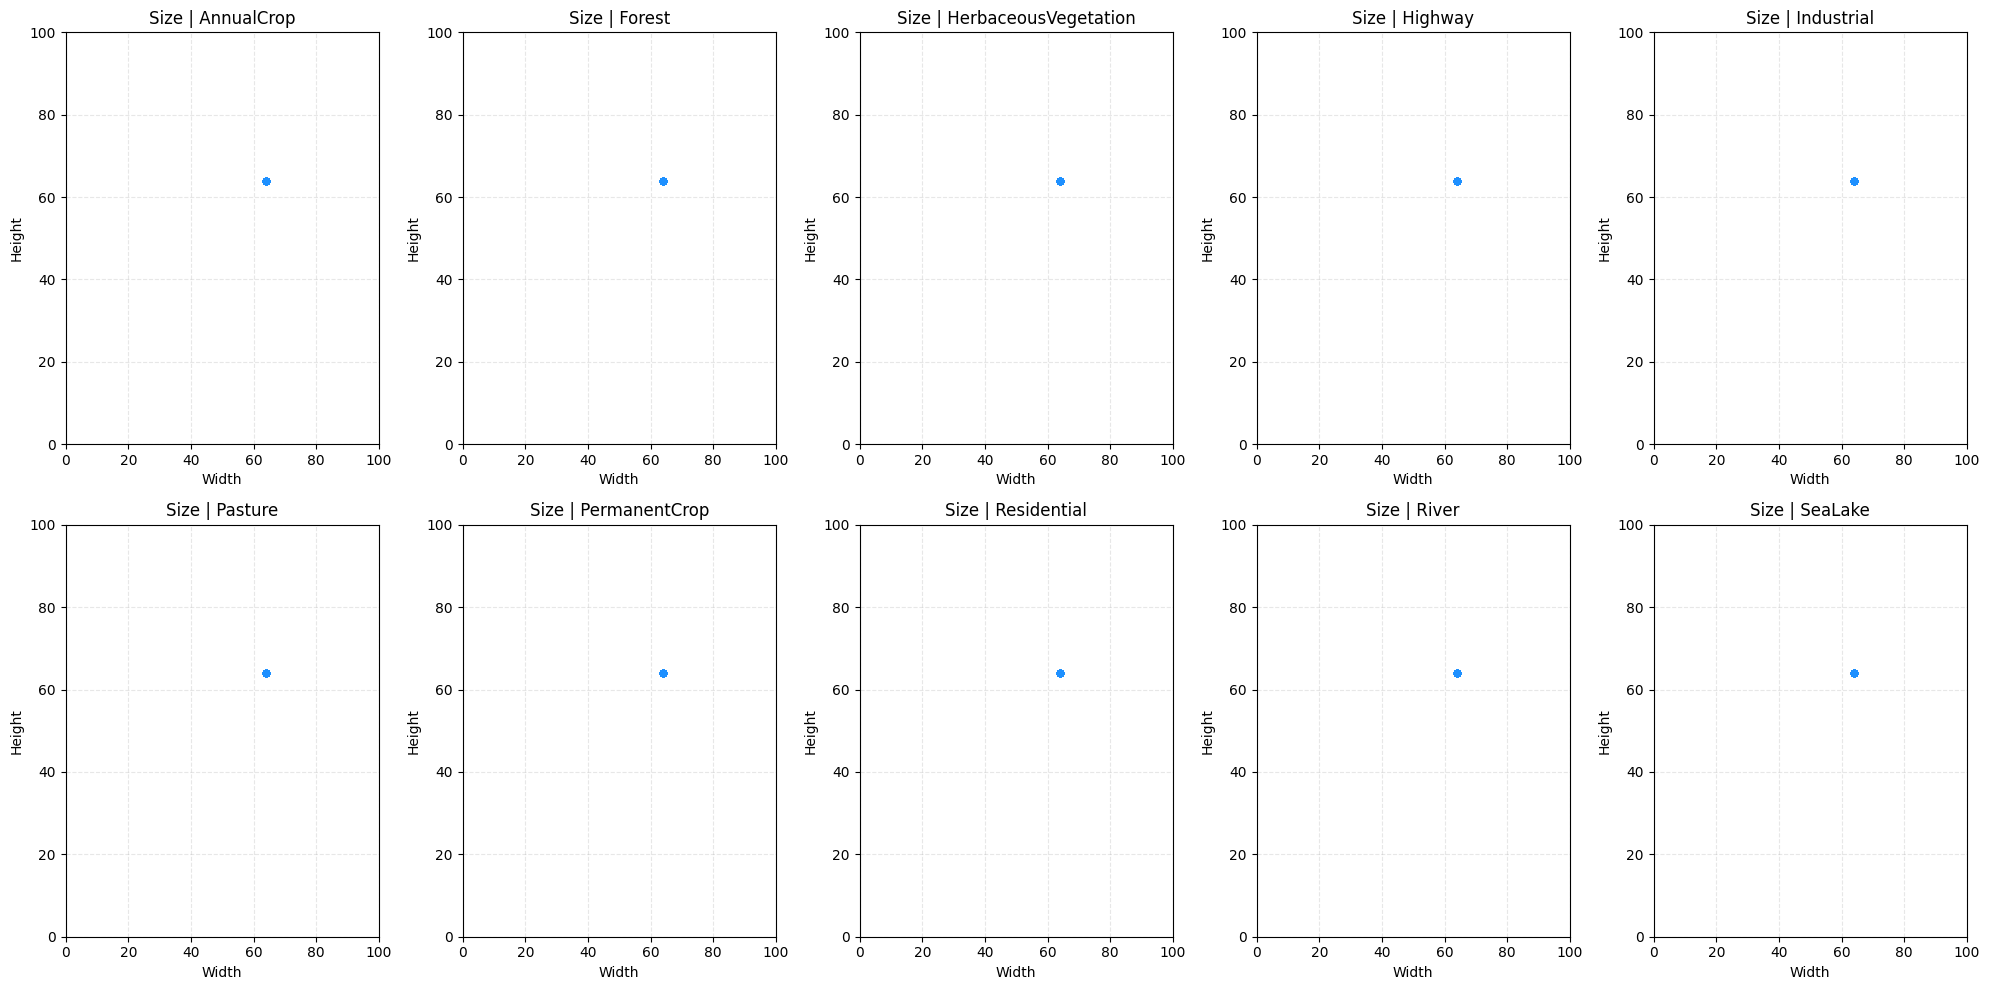

In [8]:
class_data = {}
for class_name in class_names:
    class_dir = os.path.join(land_patches_train_dir_path, class_name)
    images = os.listdir(class_dir)
    
    widths = []
    heights = []
    
    for img_name in images:
        if img_name.lower().endswith(('.png', '.jpg')):
            img_path = os.path.join(class_dir, img_name)
            with Image.open(img_path) as img:
                w, h = img.size
                widths.append(w)
                heights.append(h)

    class_data[class_name] = {'w': widths, 'h': heights}


fig = plt.subplots(nrows=2, ncols=5, figsize=(20, 10))
for idx, class_name in enumerate(class_names):
    ax = plt.subplot(2, 5, idx + 1)

    w = class_data[class_name]['w']
    h = class_data[class_name]['h']

    ax.scatter(w, h, alpha=0.5, s=20, color='dodgerblue')
    
    ax.set_title(f'Size | {class_name}')
    ax.set_xlabel('Width')
    ax.set_ylabel('Height')
    
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

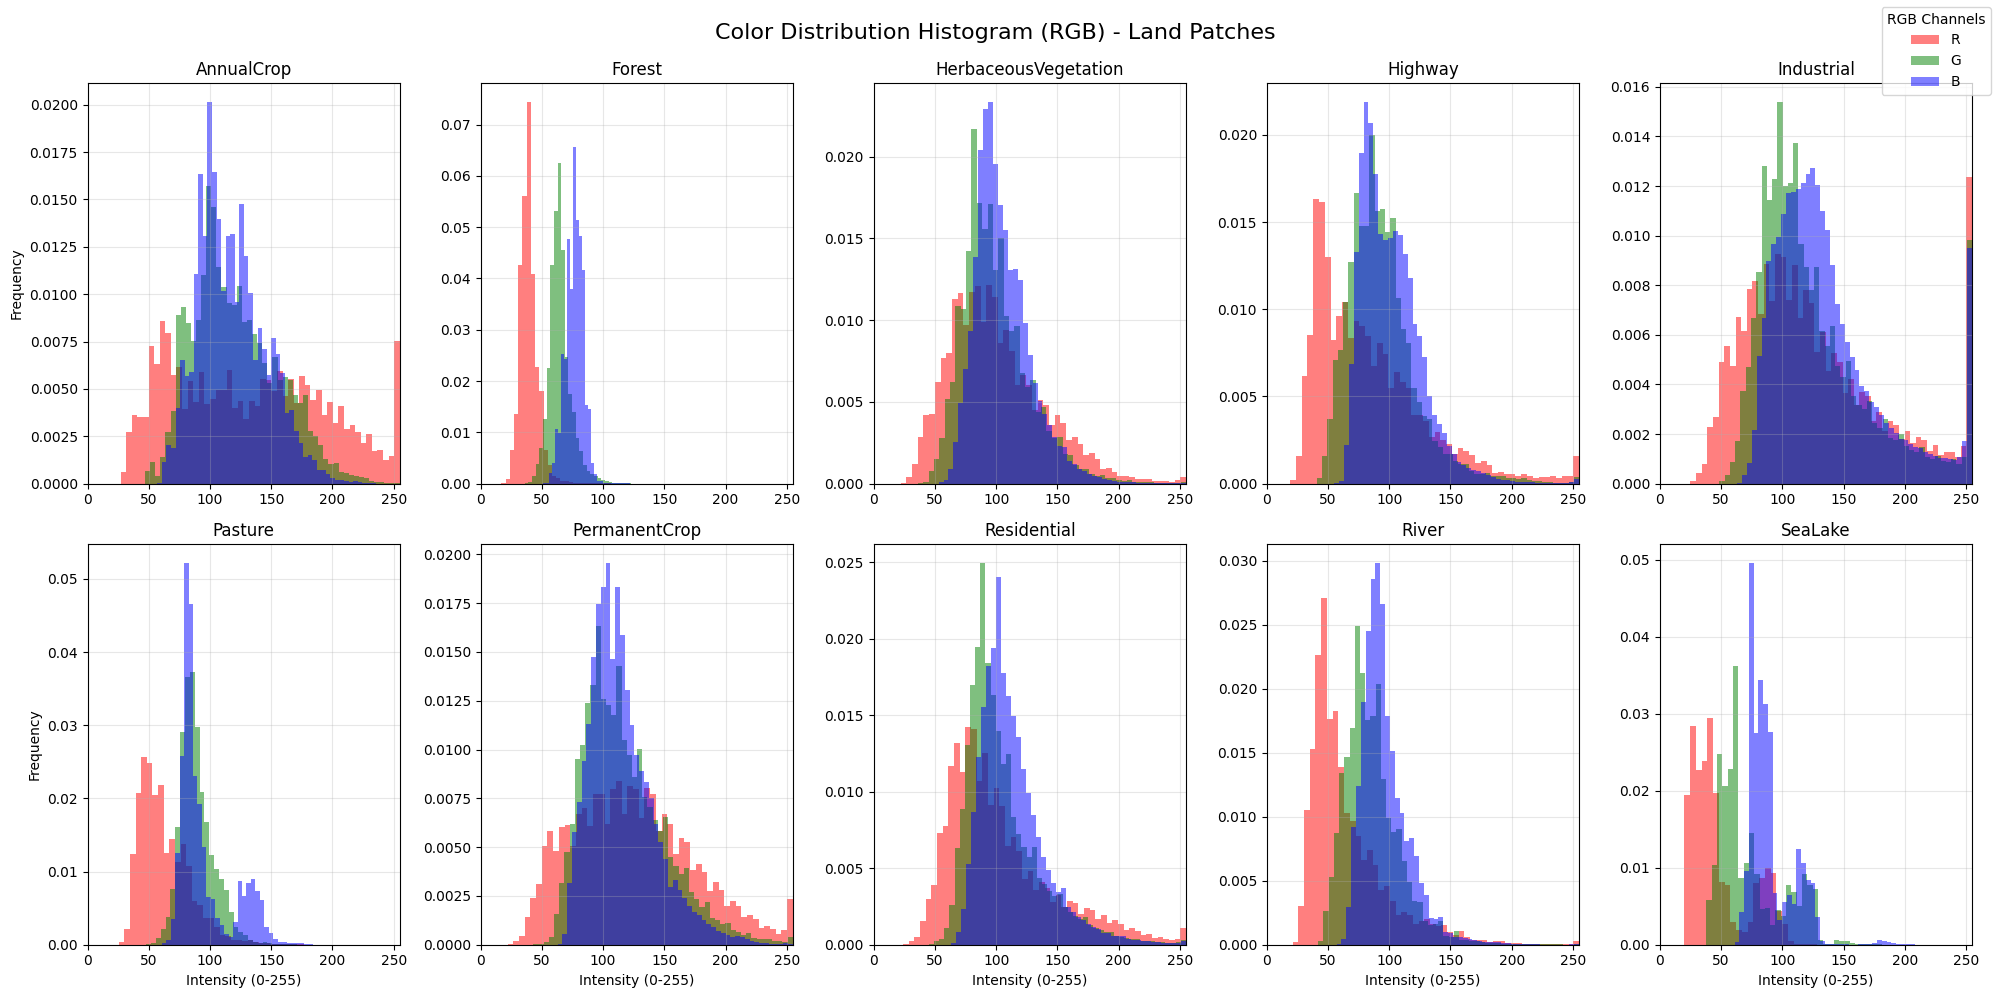

In [9]:
fig, _ = plt.subplots(nrows=2, ncols=5, figsize=(20, 10))

for idx, class_name in enumerate(class_names):
    class_dir = os.path.join(land_patches_train_dir_path, class_name)
    
    images = os.listdir(class_dir)
    if len(images) > 100:
        images = images[:100]

    all_reds = []
    all_greens = []
    all_blues = []
    
    for img_name in images:
        if img_name.lower().endswith(('.png', '.jpg')):
            img_path = os.path.join(class_dir, img_name)
            with Image.open(img_path).convert('RGB') as img:
                img_array = np.array(img)
                all_reds.extend(img_array[:, :, 0].flatten())
                all_greens.extend(img_array[:, :, 1].flatten())
                all_blues.extend(img_array[:, :, 2].flatten())
         
    ax = plt.subplot(2, 5, idx + 1)
    
    ax.hist(all_reds, bins=50, color='red', alpha=0.5, label='R', density=True)
    ax.hist(all_greens, bins=50, color='green', alpha=0.5, label='G', density=True)
    ax.hist(all_blues, bins=50, color='blue', alpha=0.5, label='B', density=True)
    ax.set_title(f'{class_name}')
    ax.set_xlim(0, 255)
    
    if idx % 5 == 0:
        ax.set_ylabel('Frequency')
    if idx >= 5:
        ax.set_xlabel('Intensity (0-255)')
        
    ax.grid(True, alpha=0.3)

handles, labels = plt.gca().get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', title="RGB Channels")

plt.suptitle("Color Distribution Histogram (RGB) - Land Patches", fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

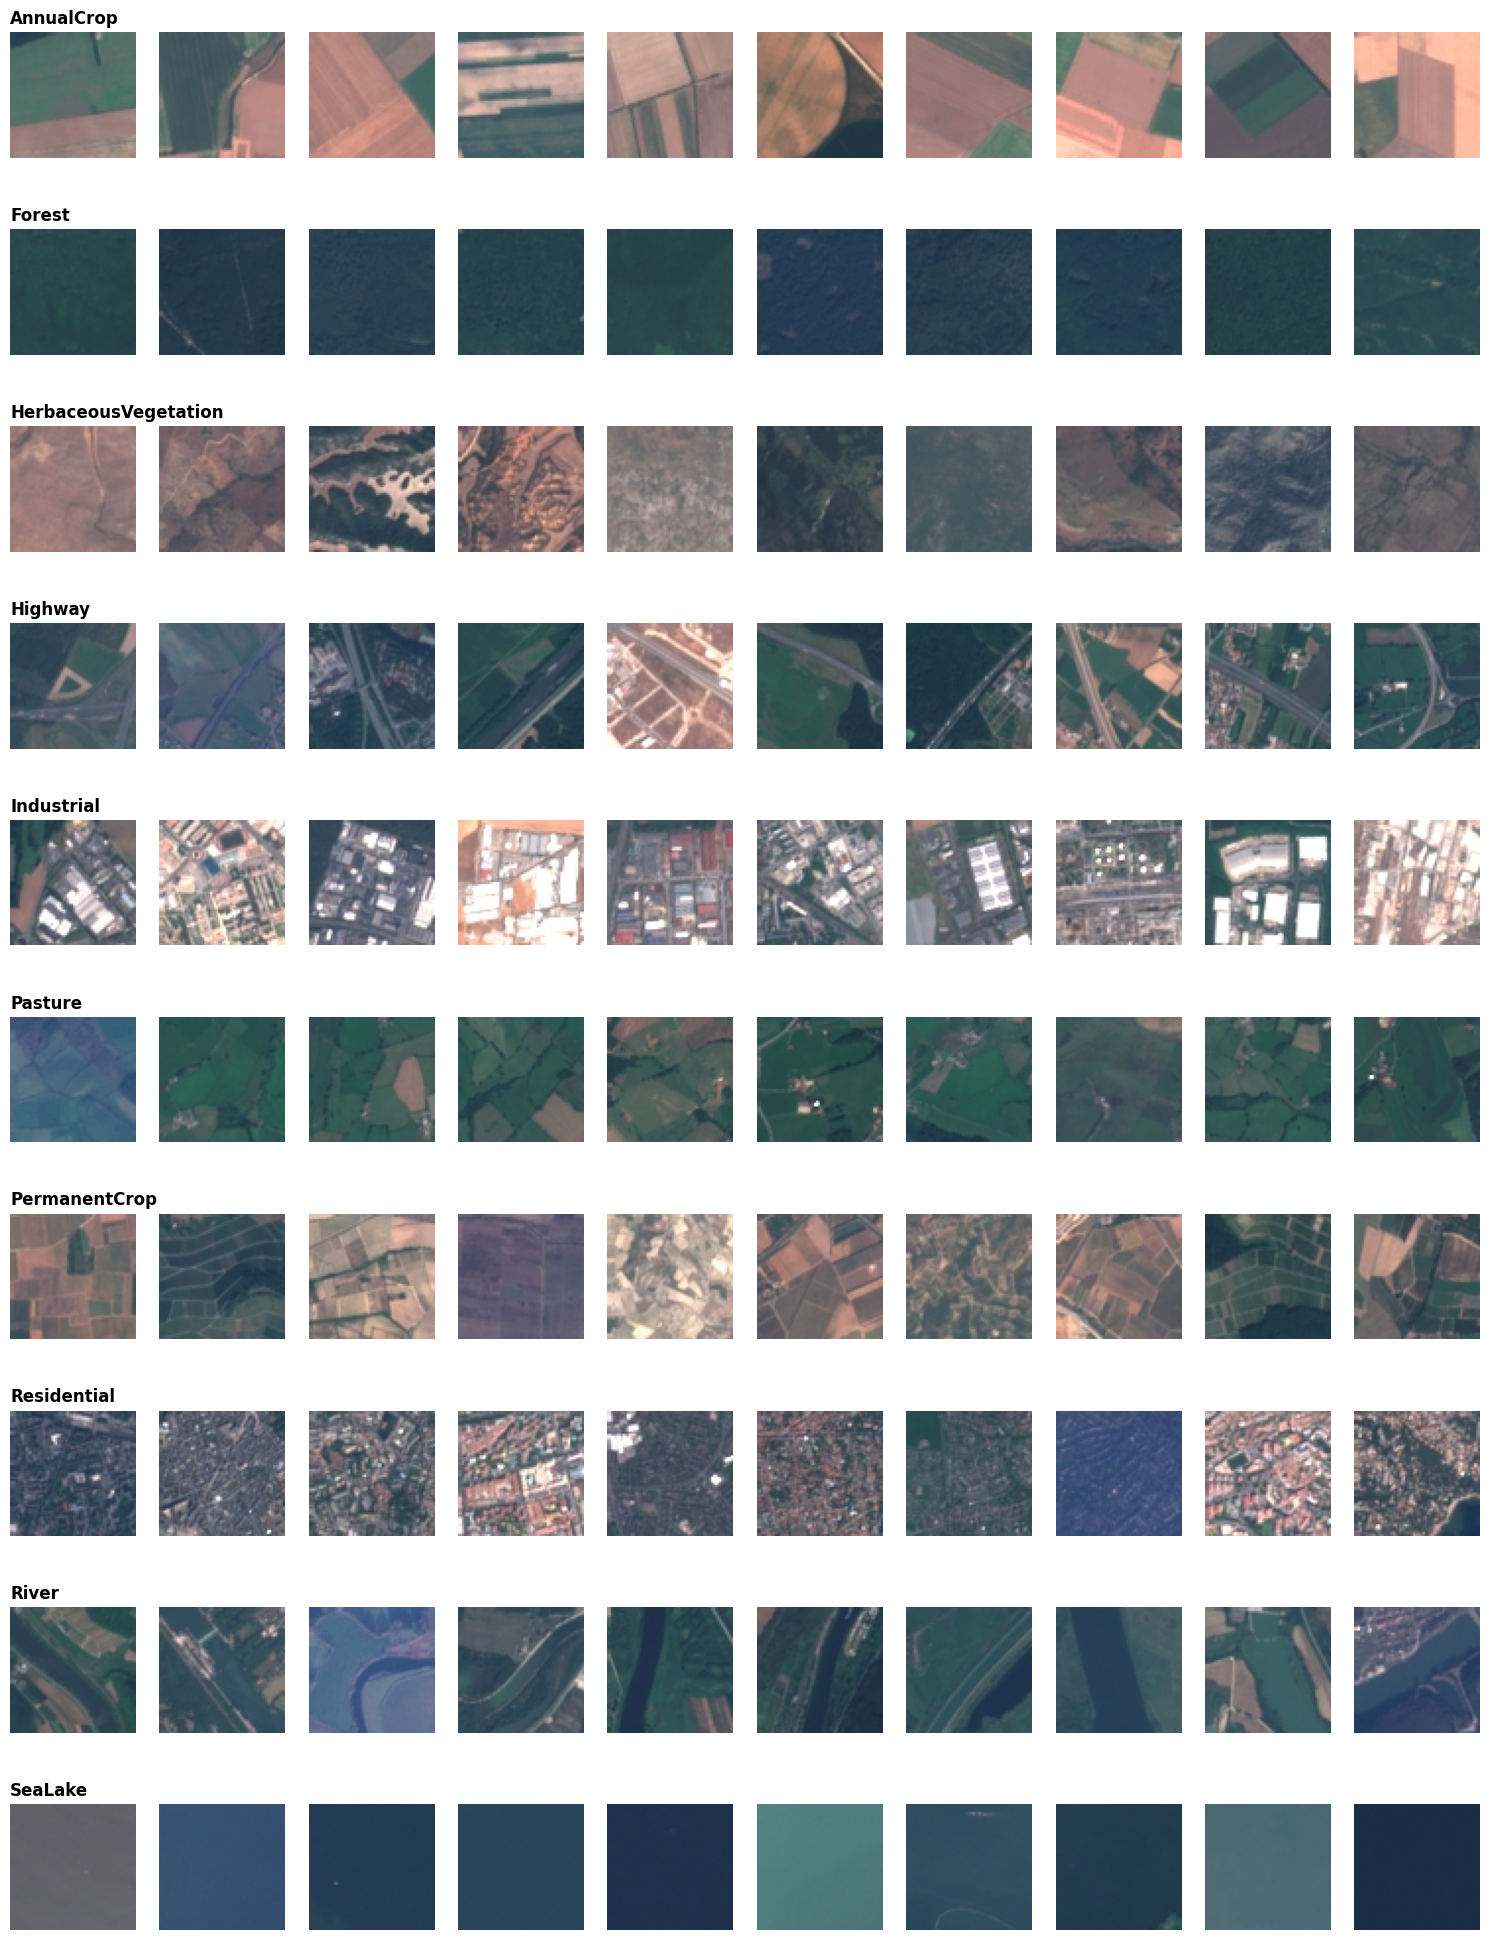

In [10]:
fig, axes = plt.subplots(nrows=len(class_names), ncols=10, figsize=(15, 20))

for row_idx, class_name in enumerate(class_names):
    class_dir = os.path.join(land_patches_train_dir_path, class_name)
    
    all_imgs = [f for f in os.listdir(class_dir) if f.lower().endswith(('.png', '.jpg'))]
    
    current_samples = random.sample(all_imgs, min(len(all_imgs), 10))
    
    for col_idx, img_name in enumerate(current_samples):
        img_path = os.path.join(class_dir, img_name)
        with Image.open(img_path) as img:
            ax = axes[row_idx, col_idx]
            ax.imshow(img)
            ax.axis('off')
            if col_idx == 0:
                ax.set_title(f'{class_name}', fontsize=12, fontweight='bold', loc='left')

plt.tight_layout()
plt.show()